# Skin Feature 재구성 — CASRN one-hot → SMILES 기반 분자 descriptor

**배경**: 기존 `skin_vectorized.csv`는 CASRN을 one-hot 컬럼으로 쓰는 방식이라, 학습에 없던 새 화합물은 feature 계산이 아예 불가능함(일반화 한계). 2026-10-06 팀 회의에서 "새로운 화합물·조합까지 예측"(연구목표 ②)을 가려면 분자구조/물리화학 기반 feature로 재구성해야 한다고 결정함.

**방법**: SMILES → RDKit descriptor 계산(A) — LogP/용해도/분자량 등 B(EPI Suite)가 원하던 물리화학적 속성도 RDKit 자체 추정치로 전부 포함되므로, A/B를 나누지 않고 RDKit 하나로 통합.

**이 노트북이 하는 일**:
1. skin_filtered.csv에서 고유 CASRN 270종 추출
2. PubChem에서 SMILES 조회(캐시 저장, 재실행 시 재조회 안 함)
3. RDKit으로 성분별 8개 descriptor 계산
4. 제형(formulation) 단위로 함량(%) 가중평균하여 성분벡터 합성
5. 라벨 결합 → `skin_vectorized.csv` 저장

> **결정 (2026-10-06, 팀)**: 기존 CASRN one-hot 버전은 **폐기 및 파일 삭제**. 새 화합물에 일반화가 안 되는 근본적 한계 때문에 성능과 무관하게 못 쓰는 방식이라, 성능 비교 대상이 아니라 교체 대상임.

In [1]:
import os
import time
import json as _json
import urllib.request
import urllib.error
import urllib.parse

import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen

BASE = os.path.dirname(os.path.abspath("__file__")) if "__file__" in dir() else os.getcwd()
# 노트북을 skin irritation 폴더 안에서 실행한다고 가정 (경로 꼬이면 아래를 직접 절대경로로 바꿔도 됨)
BASE = r"C:\Users\UserK\학술제\skin irritation"
print("작업 폴더:", BASE)

작업 폴더: C:\Users\UserK\학술제\skin irritation


## 1단계 — 고유 CASRN 목록 추출

`skin_filtered.csv`(1,799행, record 단위)에서 CASRN이 식별된 성분만 추려 고유값을 뽑습니다. 544개 제형에 흩어져 있는 성분이지만, 화학구조는 CASRN당 하나뿐이라 **270종만 조회하면 충분**합니다(같은 성분이 여러 제형에 중복 사용됨).

In [2]:
filtered = pd.read_csv(rf"{BASE}\skin_filtered.csv")
casrns = sorted(filtered["casrn"].dropna().unique().tolist())
print(f"고유 CASRN: {len(casrns)}종")
casrns[:5]

고유 CASRN: 270종


['10049-04-4', '101200-48-0', '102851-06-9', '103361-09-7', '104-55-2']

## 2단계 — PubChem에서 SMILES 조회

**주의사항 (실제로 겪은 이슈들)**:
- PubChem API가 간헐적으로 503(서비스 과부하)을 반환함 → 재시도 로직 필수
- 극히 일부(5종 내외)는 CASRN으로 이름 검색이 안 됨 → UVCB(구조식이 단일하지 않은 물질군, 예: 지방산염·식물추출오일) 또는 데이터 오류
- **발견한 데이터 오류**: `skin_filtered.csv`의 CASRN 2건이 엑셀 자동변환으로 날짜 형식처럼 깨져 있었음(기존에 `XGB.xlsx`에서 발견된 것과 동일한 유형의 버그) —
  - `1951-03-06` → 원래는 `51-03-6` (Piperonyl butoxide)
  - `8018-01-07` → 원래는 `8018-01-7` (Mancozeb)
  - 아래 `MANUAL_FIXES`로 보정 후 재조회함.
- `1312-76-1`(Potassium silicate)은 CASRN 이름 검색은 실패했지만 **화합물명으로 재검색하면 찾아짐** → 함께 보정.

**캐시**: `casrn_smiles_cache.csv`가 이미 있으면 재조회하지 않고 그대로 불러옵니다(API 호출 절약, 재실행 시 몇 초 안에 끝남).

In [3]:
CACHE_PATH = rf"{BASE}\casrn_smiles_cache.csv"

def fetch_smiles_by_query(query, by="name"):
    url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/{by}/{urllib.parse.quote(query)}/property/SMILES/JSON"
    with urllib.request.urlopen(url, timeout=15) as r:
        data = _json.loads(r.read())
        prop = data["PropertyTable"]["Properties"][0]
        return prop["CID"], prop["SMILES"]

if os.path.exists(CACHE_PATH):
    print("기존 캐시 로드:", CACHE_PATH)
    cache = pd.read_csv(CACHE_PATH)
else:
    print(f"{len(casrns)}개 CASRN 신규 조회 시작 (몇 분 소요)")
    results = []
    for i, casrn in enumerate(casrns):
        status = "found"
        cid = smiles = None
        for attempt in range(3):
            try:
                cid, smiles = fetch_smiles_by_query(casrn, by="name")
                status = "found"
                break
            except urllib.error.HTTPError as e:
                status = f"http_error_{e.code}"
                time.sleep(2 + attempt * 2)
            except Exception as e:
                status = f"error_{type(e).__name__}"
                time.sleep(2 + attempt * 2)
        results.append({"casrn": casrn, "cid": cid, "smiles": smiles, "status": status})
        time.sleep(0.3)
        if (i + 1) % 30 == 0:
            print(f"  {i+1}/{len(casrns)}")
    cache = pd.DataFrame(results)
    cache.to_csv(CACHE_PATH, index=False)

print(cache["status"].value_counts())

기존 캐시 로드: C:\Users\UserK\학술제\skin irritation\casrn_smiles_cache.csv
status
found                   261
http_error_404            6
found_via_manual_fix      3
Name: count, dtype: int64


In [4]:
# CASRN 날짜오염 2건 + 이름기반 보완 1건 수동 보정
MANUAL_FIXES = {
    "1312-76-1": ("name", "Potassium silicate"),   # 이름 검색은 되지만 CASRN 검색은 실패
    "1951-03-06": ("name", "51-03-6"),              # 엑셀이 날짜로 오인식한 CASRN -> 올바른 CASRN으로 재조회
    "8018-01-07": ("name", "8018-01-7"),
}

for casrn, (by, query) in MANUAL_FIXES.items():
    mask = cache["casrn"] == casrn
    if not mask.any() or cache.loc[mask, "status"].iloc[0].startswith("found"):
        continue
    try:
        cid, smiles = fetch_smiles_by_query(query, by=by)
        cache.loc[mask, ["cid", "smiles", "status"]] = [cid, smiles, "found_via_manual_fix"]
        print(f"보정 성공: {casrn} <- {query}")
    except Exception as e:
        print(f"보정 실패: {casrn} <- {query} ({e})")

cache.to_csv(CACHE_PATH, index=False)
print()
print(cache["status"].value_counts())
print()
print("끝내 미해결(구조 자체가 단일하지 않은 UVCB성/무기화합물 등으로 추정):")
unresolved = cache[~cache["status"].isin(["found", "found_via_manual_fix"])]
print(unresolved["casrn"].tolist())


status
found                   261
http_error_404            6
found_via_manual_fix      3
Name: count, dtype: int64

끝내 미해결(구조 자체가 단일하지 않은 UVCB성/무기화합물 등으로 추정):
['12069-69-1', '61789-71-7', '8007-46-3', '8046-74-0', '84776-33-0', '9003-13-8']


## 3단계 — RDKit descriptor 계산

SMILES가 확보된 성분마다 8개 descriptor를 계산합니다:

| descriptor | 의미 |
|---|---|
| `MolWt` | 분자량 |
| `LogP` | 지용성/수용성 정도 (Crippen 추정법) |
| `TPSA` | 극성 표면적 |
| `HBD` / `HBA` | 수소결합 공여/수용 개수 |
| `RotatableBonds` | 회전 가능 결합 수 (분자 유연성) |
| `AromaticProportion` | 방향족 원자 비율 |
| `ESOL_LogS` | 수용해도 추정치 (Delaney 2004 공식 — LogP/분자량/RotatableBonds/방향족비율만으로 계산되는 근사식, 별도 도구 없이 RDKit 출력값만으로 산출) |

이 8개가 팀 회의에서 B(EPI Suite)로 얻으려던 LogP·용해도·분자량을 전부 포함합니다 — 단, EPI Suite 조회값이 아니라 **구조에서 직접 계산한 값**이라 새 화합물에도 즉시 적용 가능합니다.

**⚠ 염 제거(salt stripping) 처리**: 264종 중 29종(11%)이 Na+/K+/Cu2+ 같은 대응이온이 붙은 염·금속착물 형태(SMILES에 `.`로 구분된 여러 조각)였습니다. 그대로 계산하면 **대응이온까지 분자량·LogP에 섞여 들어가** 값이 왜곡됩니다(예: Potassium silicate는 K+ 두 개가 섞여서 LogP가 -9.4까지 나왔는데, 핵심 성분만 보면 -3.45). 그래서 `Chem.GetMolFrags()`로 조각을 나눈 뒤 **가장 큰 조각(heavy atom 최다)만** 남기고 descriptor를 계산합니다(신약/독성 분야 표준 전처리).

In [5]:
resolved = cache[cache["smiles"].notna()].copy()

def get_largest_fragment(mol):
    frags = Chem.GetMolFrags(mol, asMols=True)
    if len(frags) == 1:
        return mol
    return max(frags, key=lambda m: m.GetNumHeavyAtoms())

def compute_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    mol = get_largest_fragment(mol)  # 염/대응이온 제거 -- 핵심 성분 하나만 남김
    n_heavy = mol.GetNumHeavyAtoms()
    n_aromatic = sum(1 for a in mol.GetAtoms() if a.GetIsAromatic())
    arom_prop = n_aromatic / n_heavy if n_heavy > 0 else 0.0
    mw = Descriptors.MolWt(mol)
    logp = Crippen.MolLogP(mol)
    rotb = Descriptors.NumRotatableBonds(mol)
    esol_logs = 0.16 - 0.63 * logp - 0.0062 * mw + 0.066 * rotb - 0.74 * arom_prop
    return {
        "MolWt": mw, "LogP": logp, "TPSA": Descriptors.TPSA(mol),
        "HBD": Descriptors.NumHDonors(mol), "HBA": Descriptors.NumHAcceptors(mol),
        "RotatableBonds": rotb, "AromaticProportion": arom_prop, "ESOL_LogS": esol_logs,
    }

desc_rows = []
for _, r in resolved.iterrows():
    d = compute_descriptors(r["smiles"])
    if d is not None:
        d["casrn"] = r["casrn"]
        desc_rows.append(d)

desc = pd.DataFrame(desc_rows).set_index("casrn")
DESC_COLS = desc.columns.tolist()
desc.to_csv(rf"{BASE}\casrn_descriptors.csv")
print(f"descriptor 계산 완료: {len(desc)}종 / {len(casrns)}종 ({len(desc)/len(casrns)*100:.1f}% 커버)")
desc.describe()

descriptor 계산 완료: 264종 / 270종 (97.8% 커버)


,MolWt,LogP,TPSA,HBD,HBA,RotatableBonds,AromaticProportion,ESOL_LogS
count,264.000000,264.000000,264.000000,264.000000,264.000000,264.000000,264.000000,264.000000
mean,318.345049,2.948555,65.515379,0.818182,4.166667,4.469697,0.364956,-3.646396
std,133.080519,2.106075,37.808501,0.917247,2.563762,2.939024,0.233703,1.851425
min,32.067000,-3.445600,0.000000,0.000000,0.000000,0.000000,0.000000,-8.270860
25%,226.826500,1.389265,40.620000,0.000000,2.000000,3.000000,0.247500,-4.759352
50%,315.082500,3.034550,57.160000,1.000000,4.000000,4.000000,0.423077,-3.659671
75%,388.362500,4.279610,83.695000,1.000000,5.000000,6.000000,0.500000,-2.572243
max,886.133000,8.994300,191.980000,4.000000,14.000000,19.000000,1.000000,1.618493


## 4단계 — 제형 단위 가중평균 벡터화

성분별 descriptor를 **함량(%) 가중평균**으로 합쳐 제형 하나의 feature로 만듭니다. 실제로 테스트하며 걸린 edge case 2개를 여기서 같이 처리합니다:

1. **함량% 결측(8건, 전부 단일성분)**: 가중치를 결측으로 두면 평균 계산이 아예 안 됨 → 동일가중치(1)로 대체. 단일성분이라 가중치 값 자체는 결과에 영향 없음(평균을 낼 대상이 하나뿐이므로).
2. **함량% 0으로 중복 기록(2건, MIX328/385 — 동물 여러 마리 반복시험으로 같은 성분이 중복 기록되며 둘 다 0%)**: 가중치 합이 0이 되어 나눗셈 오류 발생 → 전부 0%인 경우에만 균등가중치로 대체.
3. **(formulation_id, casrn) 중복행**: 같은 이유로 중복될 수 있어 집계 전에 첫 값만 남김(기존 파이프라인과 동일한 방식).

In [6]:
labels = pd.read_csv(rf"{BASE}\skin_formulation_level_with_comp_group.csv")

known = filtered.dropna(subset=["casrn"]).copy()
known = known.drop_duplicates(subset=["formulation_id", "casrn"], keep="first")
known["has_descriptor"] = known["casrn"].isin(desc.index)

rows = []
for fid, grp in known.groupby("formulation_id"):
    g_resolved = grp[grp["has_descriptor"]]
    g_unresolved = grp[~grp["has_descriptor"]]

    resolved_pct = g_resolved["percent_active_ingredient"].fillna(0).sum()
    unresolved_structure_pct = g_unresolved["percent_active_ingredient"].fillna(0).sum()
    has_missing_pct = g_resolved["percent_active_ingredient"].isna().any()

    row = {
        "formulation_id": fid,
        "resolved_pct": resolved_pct,
        "has_missing_pct": has_missing_pct,
        "unresolved_structure_pct": unresolved_structure_pct,
        "has_missing_structure": len(g_unresolved) > 0,
    }

    if len(g_resolved) > 0:
        w = g_resolved["percent_active_ingredient"].fillna(1.0).values
        used_equal_weight_fallback = False
        if w.sum() == 0:
            w = np.ones_like(w)
            used_equal_weight_fallback = True
        row["used_equal_weight_fallback"] = used_equal_weight_fallback
        d = desc.loc[g_resolved["casrn"]].values
        weighted = (w[:, None] * d).sum(axis=0) / w.sum()
        for col, val in zip(DESC_COLS, weighted):
            row[col] = val
    else:
        row["used_equal_weight_fallback"] = False
        for col in DESC_COLS:
            row[col] = np.nan

    rows.append(row)

agg = pd.DataFrame(rows)
print("완전 미해결(descriptor 전부 NaN) 제형 수:", agg["MolWt"].isna().sum())
agg.head(3)

완전 미해결(descriptor 전부 NaN) 제형 수: 1


,formulation_id,resolved_pct,has_missing_pct,unresolved_structure_pct,has_missing_structure,used_equal_weight_fallback,MolWt,LogP,TPSA,HBD,HBA,RotatableBonds,AromaticProportion,ESOL_LogS
0,MIX1,0.08,False,0.0,False,False,339.325000,1.119300,128.490000,0.000000,7.000000,4.000000,0.260870,-2.578017
1,MIX10,25.50,False,0.0,False,False,371.442329,3.741698,88.496235,0.286275,6.568627,6.427451,0.585686,-4.509408
2,MIX100,75.00,False,0.0,False,False,317.820000,3.566200,50.940000,1.000000,3.000000,3.000000,0.500000,-4.229190


## 5단계 — 메타정보·라벨 결합 + 저장

기존 `skin_vectorized.csv`와 동일한 메타 컬럼 체계(comp_count, unknown_pct, comp_group_id, final_label, binary_label 등)를 유지하고, 새로 추가된 `undeclared_pct`(FIFRA 미기재 비활성성분 비율 — eye팀 방식과 통일, 기존 skin 버전에 없던 컬럼)까지 포함해서 저장합니다.

In [7]:
meta = filtered.groupby("formulation_id").agg(
    unknown_pct=("unknown_pct", "first"),
    has_unknown_ingredient=("is_unknown_ingredient", "any"),
).reset_index()
comp_count = known.groupby("formulation_id")["casrn"].nunique().rename("comp_count").reset_index()

final = (agg
         .merge(meta, on="formulation_id", how="left")
         .merge(comp_count, on="formulation_id", how="left"))

final["is_single_component"] = final["comp_count"] == 1
final["undeclared_pct"] = (100 - final["resolved_pct"] - final["unresolved_structure_pct"]
                            - final["unknown_pct"]).clip(lower=0)

final = final.merge(
    labels[["formulation_id", "final_label", "comp_group_id", "is_composition_twin", "internal_conflict_resolved"]],
    on="formulation_id", how="left", validate="one_to_one",
)
final["binary_label"] = final["final_label"].map(lambda x: 1 if x in (1, 2) else 0)

meta_cols = ["formulation_id", "comp_count", "is_single_component",
             "resolved_pct", "has_missing_pct", "used_equal_weight_fallback",
             "unresolved_structure_pct", "has_missing_structure",
             "unknown_pct", "has_unknown_ingredient", "undeclared_pct",
             "comp_group_id", "is_composition_twin", "internal_conflict_resolved",
             "final_label", "binary_label"]
final = final[meta_cols + DESC_COLS]

final.to_csv(rf"{BASE}\skin_vectorized.csv", index=False)
print("저장 완료:", final.shape)

저장 완료: (544, 24)


## 검증 (QC)

이전 CASRN one-hot 버전 파일은 완전히 폐기·삭제됐기 때문에(비교 대상 자체가 없음), 여기서는 **알려진 정답값(이전에 직접 확인해둔 라벨 분포)과 대조**하는 자기완결적 검증으로 대체합니다 — feature만 교체되고 라벨/제형 수가 안 깨졌는지 확인하는 목적은 동일.

In [8]:
EXPECTED_N_ROWS = 544
EXPECTED_BINARY_COUNTS = {0: 515, 1: 29}

print("행 개수 기대값과 일치?", len(final) == EXPECTED_N_ROWS, f"(실제 {len(final)})")
print()
print("binary_label 분포:"); print(final["binary_label"].value_counts())
print("기대값과 일치?", final["binary_label"].value_counts().to_dict() == EXPECTED_BINARY_COUNTS)
print()
print("구조 완전 미해결(descriptor 전부 NaN):", final["MolWt"].isna().sum(), "건")
print(final[final["MolWt"].isna()][["formulation_id", "comp_count", "unresolved_structure_pct"]])

행 개수 기대값과 일치? True (실제 544)

binary_label 분포:
binary_label
0    515
1     29
Name: count, dtype: int64
기대값과 일치? True

구조 완전 미해결(descriptor 전부 NaN): 1 건
    formulation_id  comp_count  unresolved_structure_pct
198         MIX306           1                      2.02


## 결과 시각화 — feature가 실제로 어떻게 나왔는지 보기

지금까지는 숫자(개수·%)로만 확인했는데, 여기서부터는 **feature 값 자체가 어떤 분포로 나왔는지, 독성/비독성 사이에 차이가 보이는지**를 그림으로 확인.

In [9]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

_font_path = r"C:\Windows\Fonts\malgun.ttf"
fm.fontManager.addfont(_font_path)
plt.rcParams["font.family"] = fm.FontProperties(fname=_font_path).get_name()
plt.rcParams["axes.unicode_minus"] = False

SURFACE = "#fcfcfb"; INK = "#0b0b0b"; MUTED = "#898781"; GRID_C = "#e1e0d9"; BASE_C = "#c3c2b7"
GOOD = "#0ca30c"; CRIT = "#d03b3b"; BLUE = "#2a78d6"
%matplotlib inline

### ① SMILES 커버리지 — 270종 중 몇 종이나 구조를 확보했나

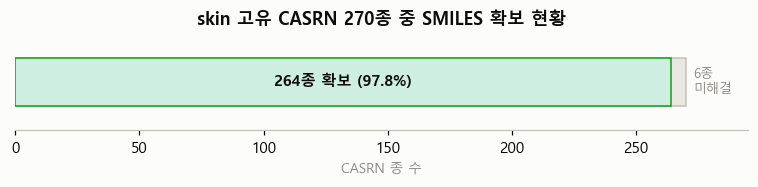

In [10]:
fig, ax = plt.subplots(figsize=(7, 1.8), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
n_found = cache["smiles"].notna().sum()
n_total = len(cache)
ax.barh([0], [n_total], color="#e8e7e2", edgecolor=BASE_C, height=0.5, zorder=2)
ax.barh([0], [n_found], color="#cdeee1", edgecolor=GOOD, height=0.5, zorder=3)
ax.text(n_found / 2, 0, f"{n_found}종 확보 ({n_found/n_total*100:.1f}%)", ha="center", va="center",
        fontsize=10, fontweight="bold", color=INK)
ax.text(n_total + 3, 0, f"{n_total - n_found}종\n미해결", ha="left", va="center", fontsize=8.5, color=MUTED)
ax.set_xlim(0, n_total + 25); ax.set_ylim(-0.5, 0.5)
ax.set_yticks([]); ax.set_xlabel("CASRN 종 수", fontsize=9, color=MUTED)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(BASE_C)
ax.set_title("skin 고유 CASRN 270종 중 SMILES 확보 현황", fontsize=11.5, color=INK, fontweight="bold")
plt.tight_layout(); plt.show()

### ② 8개 descriptor 분포 — 264종 성분이 어떤 값 범위에 퍼져 있나

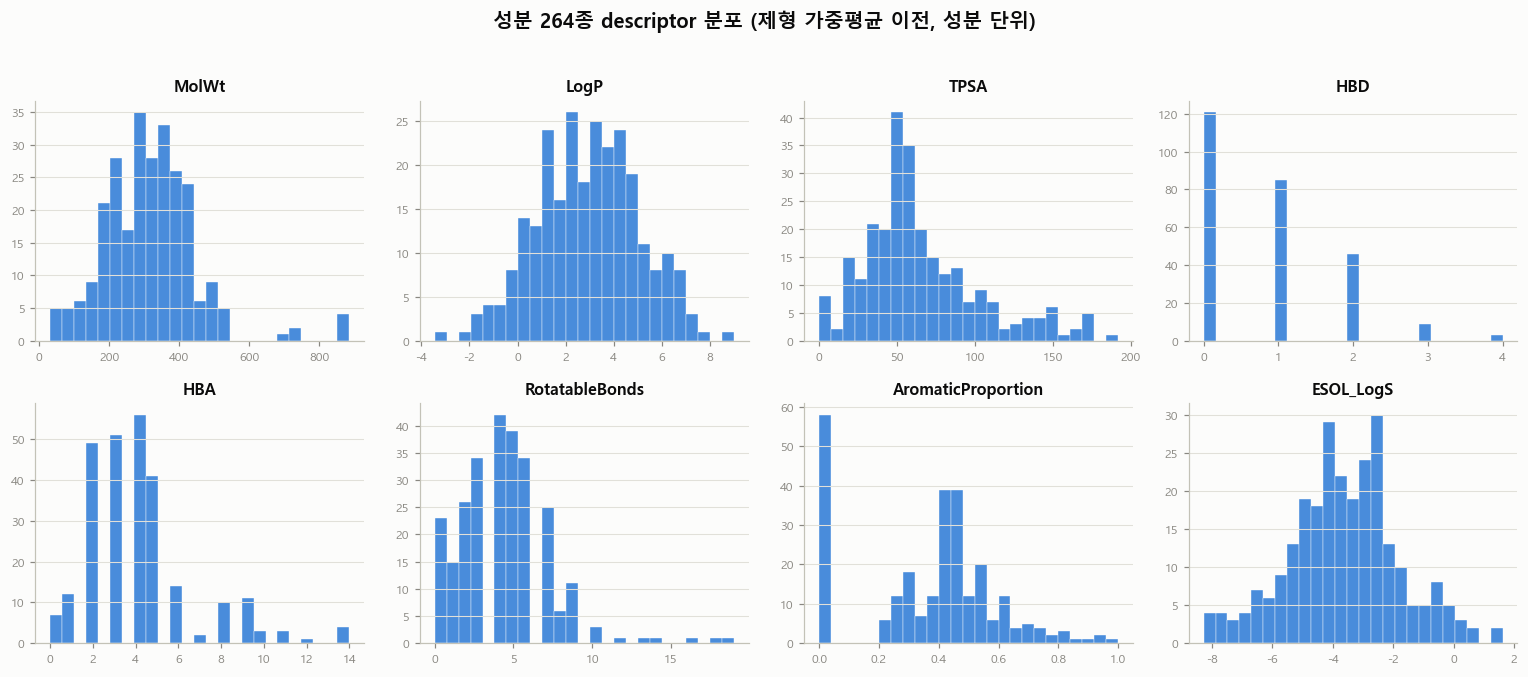

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6), facecolor=SURFACE)
for ax, col in zip(axes.flat, DESC_COLS):
    ax.set_facecolor(SURFACE)
    ax.hist(desc[col].dropna(), bins=25, color=BLUE, alpha=0.85, edgecolor="white", linewidth=0.3)
    ax.set_title(col, fontsize=10.5, color=INK, fontweight="bold")
    ax.tick_params(labelsize=8, colors=MUTED)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(BASE_C); ax.spines["bottom"].set_color(BASE_C)
    ax.grid(axis="y", color=GRID_C, linewidth=0.7, zorder=0)
fig.suptitle("성분 264종 descriptor 분포 (제형 가중평균 이전, 성분 단위)", fontsize=13, color=INK, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

### ③ descriptor 간 상관관계 — 서로 겹치는 정보는 없는지 확인

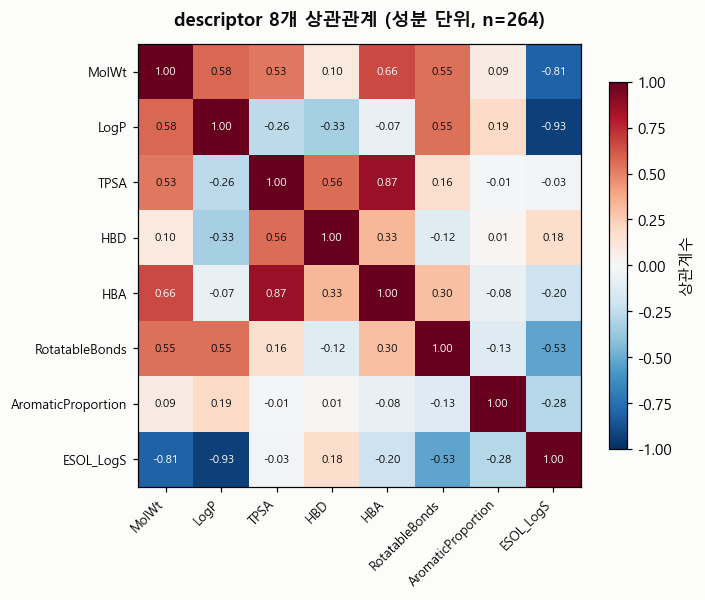

In [12]:
corr = desc[DESC_COLS].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5), facecolor=SURFACE)
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(DESC_COLS))); ax.set_xticklabels(DESC_COLS, rotation=45, ha="right", fontsize=8.5)
ax.set_yticks(range(len(DESC_COLS))); ax.set_yticklabels(DESC_COLS, fontsize=8.5)
for i in range(len(DESC_COLS)):
    for j in range(len(DESC_COLS)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="상관계수")
ax.set_title("descriptor 8개 상관관계 (성분 단위, n=264)", fontsize=12, color=INK, fontweight="bold", pad=12)
plt.tight_layout(); plt.show()

**관찰**: `ESOL_LogS`와 `LogP`가 -0.93으로 거의 선형 종속 — ESOL 공식 자체가 `-0.63×LogP` 항을 포함하니 당연한 결과지만, **둘 다 feature로 같이 넣으면 중복정보**라는 뜻. Kang2023 벤치마크 논문도 Pearson `|r|≥0.9` 기준으로 다중공선성 제거를 했으니(진행상황.md 참고), 모델링 단계에서 이 둘 중 하나를 빼거나 PCA로 묶는 걸 검토할 것.

### ④ 독성(1) vs 비독성(0) — feature가 라벨과 관련 있어 보이는지 1차 확인

모델을 돌리기 전에, 제형 단위로 합성한 feature가 라벨과 **눈으로 봐도 차이가 나는지** 먼저 확인합니다. 차이가 전혀 안 보여도 모델이 못 배운다는 뜻은 아니지만(비선형 조합으로 배울 수 있음), 차이가 보이면 최소한 '이 feature가 헛짓은 아니다'는 심증은 얻을 수 있습니다.

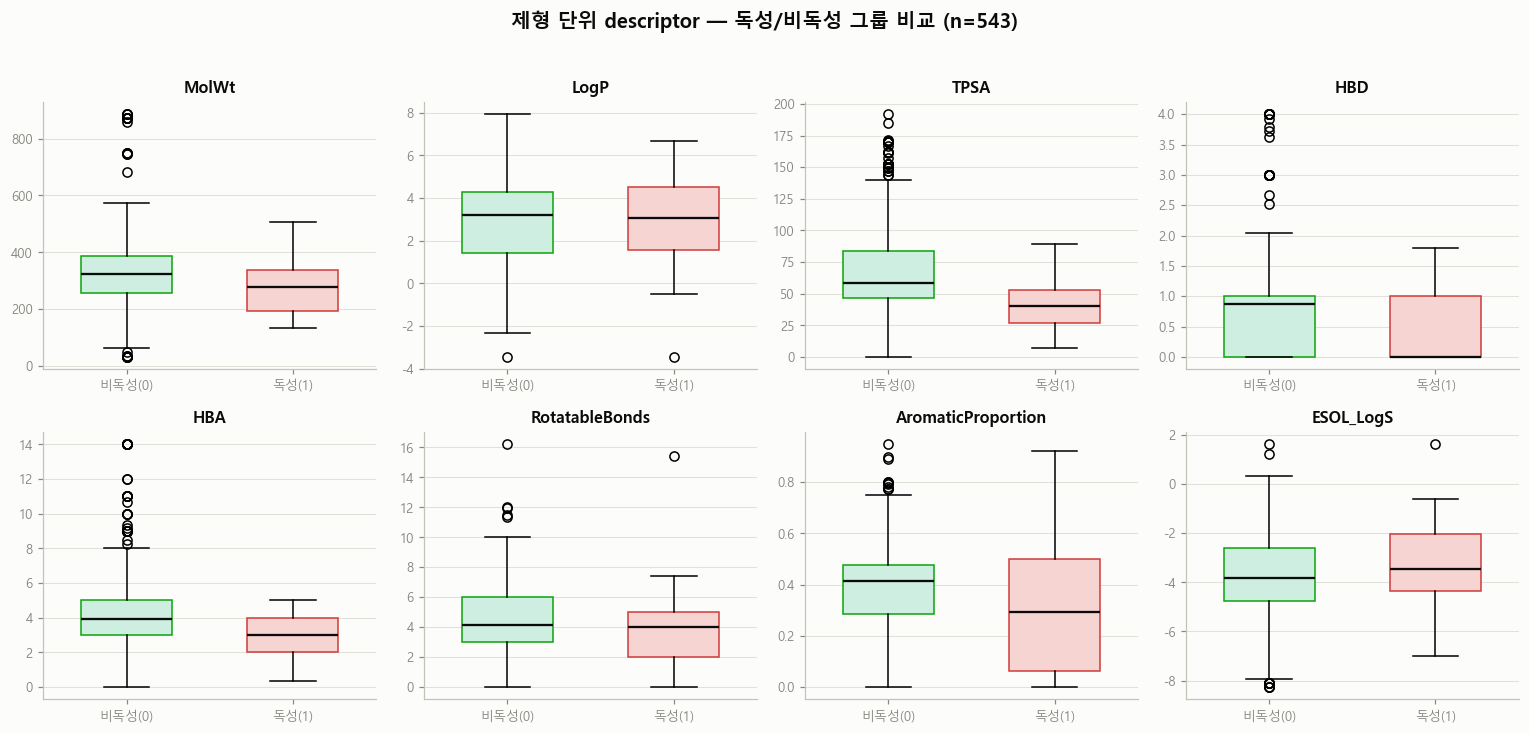

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5), facecolor=SURFACE)
plot_df = final.dropna(subset=DESC_COLS)
for ax, col in zip(axes.flat, DESC_COLS):
    ax.set_facecolor(SURFACE)
    data0 = plot_df.loc[plot_df["binary_label"] == 0, col]
    data1 = plot_df.loc[plot_df["binary_label"] == 1, col]
    bp = ax.boxplot([data0, data1], labels=["비독성(0)", "독성(1)"], patch_artist=True, widths=0.55,
                     medianprops=dict(color=INK, linewidth=1.5))
    bp["boxes"][0].set_facecolor("#cdeee1"); bp["boxes"][0].set_edgecolor(GOOD)
    bp["boxes"][1].set_facecolor("#f6d4d2"); bp["boxes"][1].set_edgecolor(CRIT)
    ax.set_title(col, fontsize=10.5, color=INK, fontweight="bold")
    ax.tick_params(labelsize=8.5, colors=MUTED)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(BASE_C); ax.spines["bottom"].set_color(BASE_C)
    ax.grid(axis="y", color=GRID_C, linewidth=0.7, zorder=0)
fig.suptitle("제형 단위 descriptor — 독성/비독성 그룹 비교 (n=543)", fontsize=13, color=INK, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

**관찰**: `TPSA`(비독성 중앙값 약 60 vs 독성 약 40)와 `AromaticProportion`(약 0.42 vs 0.29)에서 그룹 간 차이가 눈에 보임 — 극성/방향족 비율이 낮을수록 독성 쪽에 쏠리는 경향. 나머지(MolWt, LogP, HBD, HBA, RotatableBonds, ESOL_LogS)는 분포가 많이 겹쳐서 단독으로는 구분력이 약해 보임. 다만 양성(독성) 샘플이 29건뿐이라 이 그림만으로 확정하긴 이르고, 모델이 여러 descriptor를 조합해서 배울 여지는 남아있음.

## 한계점 (팀 공유 필요)

1. **완전 미해결 1건** (`MIX306`): 단일성분 제형인데 그 성분(구조식이 단일하지 않은 물질군 추정)의 SMILES를 못 찾음 → descriptor가 전부 NaN. 모델링 시 이 1건은 제외하거나 별도 처리 필요.
2. **SMILES 미해결 6종**: 대부분 UVCB(지방산염·식물오일 등 구조식이 하나로 정의 안 되는 물질군)나 무기화합물 — 애초에 "분자 하나의 구조"라는 개념 자체가 안 맞는 물질들이라 RDKit 방식의 근본적 한계.
3. ~~**ESOL_LogS 극단치**(아바멕틴 계열, 분자량 1700대에서 -16 등)~~ → **해결됨(2026-10-06, 염 제거 적용)**. 원인은 "큰 분자라서"가 아니라 **다중 프래그먼트 SMILES를 염 제거 없이 통째로 계산**했기 때문이었음 — `Chem.GetMolFrags()`로 최대 조각만 남기도록 고치니 해당 물질 MolWt 1732→873(실제 아바멕틴 B1a 분자량과 일치), ESOL_LogS -16.1→-8.1로 정상화. 같은 원인으로 29종(11%)의 descriptor가 왜곡돼 있었던 것도 함께 수정됨(예: Potassium silicate LogP -9.44→-3.45).
4. **CASRN 날짜오염은 skin_filtered.csv 원본 레벨의 문제**이므로, 이 노트북에서만 보정하지 말고 원본 파일도 고칠지 팀 논의 필요.
5. **ESOL_LogS ↔ LogP 다중공선성(상관 -0.93, 염 제거 후에도 동일)**: 공식 자체가 LogP를 포함해서 생기는 구조적 중복이라 염 제거와 무관하게 남아있음 — 모델링 전 둘 중 하나 제거 또는 PCA 검토 (시각화 ③ 참고).